# Лабораторная работа №6: Построение и оценка VLM-пайплайна

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Запустить quantized VLM 2–4B.
- Создать evaluation JSONL.
- Сравнить prompts, resolution и decoding; разметить ошибки.


## Теоретическая часть

VLM связывает visual encoder, projector и language model. Оценка должна разделять captioning, VQA, OCR и structured extraction, фиксировать prompt, decoding и ошибки: hallucination, counting, spatial relations.

![Пример изображения для Visual Question Answering](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/vqa-example.png)


### Математическая постановка

Для открытых ответов одной exact match недостаточно. Используют нормализованный EM/F1, judge rubric и ручную разметку ошибок. Hallucination rate: $H=N_{unsupported}/N_{claims}$.


### Материалы

- [Transformers multimodal chat templates](https://huggingface.co/docs/transformers/chat_templating_multimodal)
- [VLMEvalKit](https://github.com/open-compass/VLMEvalKit)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Запустить quantized VLM 2–4B.
2. Создать evaluation JSONL.
3. Сравнить prompts, resolution и decoding; разметить ошибки.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** VLM 4B NF4 inference, одно изображение.
- **Ограничение данных:** 20 evaluation examples: 5 на каждый из четырёх типов задач.
- **Fallback:** VLM 2B NF4 с тем же API.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и инференсу; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    # локально работаю на Apple Silicon, поэтому кроме CUDA проверяю MPS
    DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})

{'device': 'mps', 'fast_dev_run': False, 'data_root': '/Users/filipp/Desktop/рабочий стол/Вуз/учеба/computer_vision/computer_vision_2026/data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Оценочный набор с происхождением

*Вес: 1 балл.*

**Постановка.** Используйте PixMo-Cap, PixMo-AskModelAnything, PixMo-Docs и PixMo-Count с опубликованными эталонами и сохраняйте происхождение каждой записи; локальных файлов от студента не требуется.

Выполните следующие действия:
1. Загрузите открытые изображения и опубликованные ответы через `open_eval_data.load_open_eval`; сохраните URL, split, индекс записи и сведения о лицензировании.
2. Проверьте размер набора и наличие captioning, VQA, OCR и structured extraction.

**Результат.** eval.jsonl с проверяемыми примерами и абсолютными либо существующими путями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [3]:
from open_eval_data import load_open_eval
from PIL import Image

eval_path = ARTIFACTS / "eval.jsonl"
if eval_path.exists() and all(Path(json.loads(l)["image"]).is_file() for l in eval_path.read_text().splitlines()):
    # набор уже зафиксирован: загрузчик пропускает недоступные URL, поэтому при повторном запуске беру сохранённый состав
    examples = [json.loads(l) for l in eval_path.read_text().splitlines()]
else:
    examples = load_open_eval(root=DATA_ROOT / "lab06", per_task=1 if FAST_DEV_RUN else None)
for k, ex in enumerate(examples):
    ex["id"] = f"{ex['task']}-{ex['source_row']}"
with open(eval_path, "w") as f:
    for ex in examples:
        f.write(json.dumps(ex, ensure_ascii=False) + "\n")
tasks = {}
for ex in examples:
    tasks[ex["task"]] = tasks.get(ex["task"], 0) + 1
check(set(tasks) == {"captioning", "vqa", "ocr", "structured"}, f"есть все четыре типа задач: {tasks}")
check(all(Path(ex["image"]).is_file() for ex in examples), "все изображения существуют по абсолютным путям")
check(len({ex["id"] for ex in examples}) == len(examples), "идентификаторы примеров уникальны")
print(f"примеров: {len(examples)}", tasks)
print("лицензия:", examples[0]["license"])

✔ есть все четыре типа задач: {'captioning': 5, 'vqa': 5, 'ocr': 5, 'structured': 5}
✔ все изображения существуют по абсолютным путям
✔ идентификаторы примеров уникальны
примеров: 20 {'captioning': 5, 'vqa': 5, 'ocr': 5, 'structured': 5}
лицензия: ODC-BY-1.0 (dataset metadata; image rights may differ)


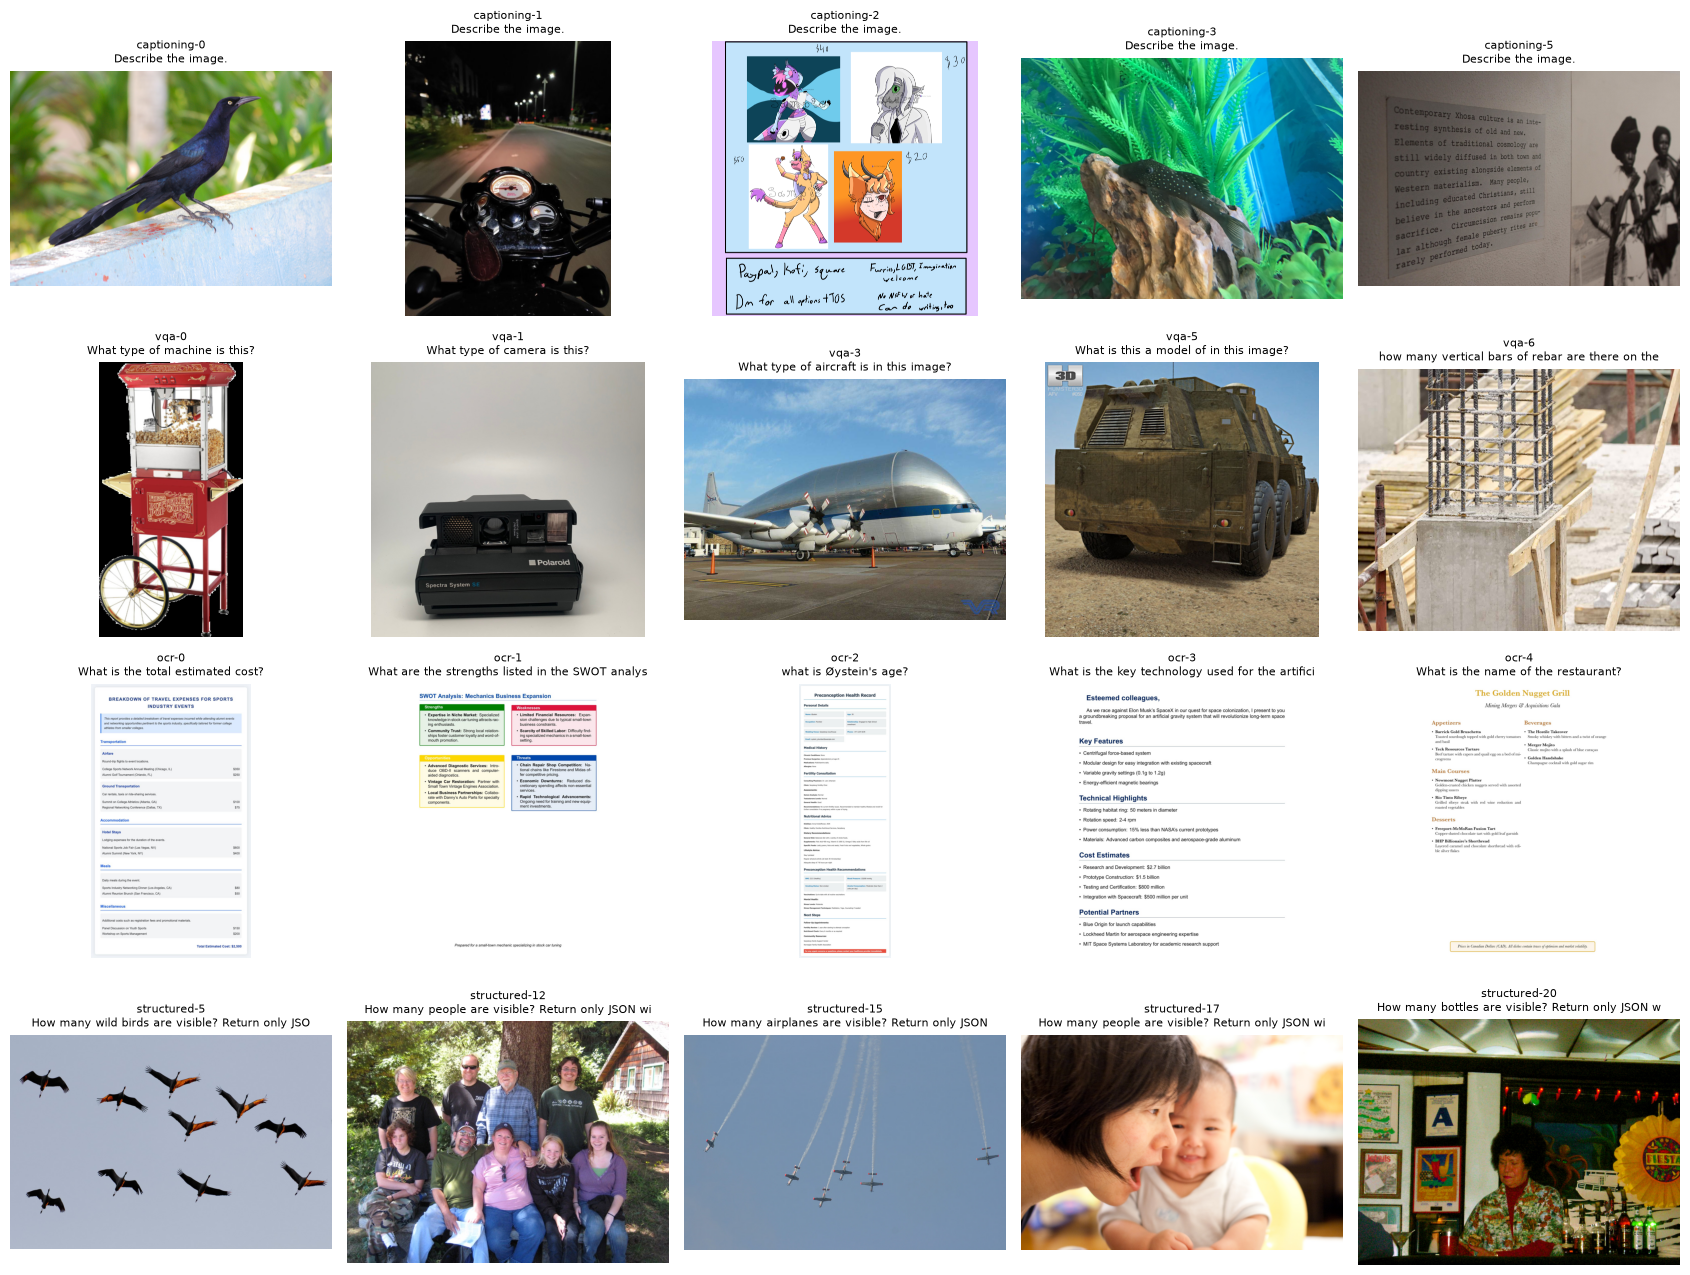

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(4, 5, figsize=(17, 13)) if len(examples) == 20 else plt.subplots(1, len(examples), figsize=(4 * len(examples), 4))
for ax, ex in zip(np.atleast_1d(axes).flat, examples):
    ax.imshow(Image.open(ex["image"]).convert("RGB")); ax.axis("off")
    ax.set_title(f"{ex['id']}\n{ex['question'][:48]}", fontsize=8)
fig.tight_layout(); fig.savefig(ARTIFACTS / "eval_preview.png", dpi=70); plt.show()

### Модель и режим квантования

*Вес: 1 балл.*

**Постановка.** Фиксация версии модели и precision нужна для интерпретации результатов инференса.

Выполните следующие действия:
1. Загрузите processor и VLM.
2. На GPU включите NF4; без GPU не запускайте полный режим.

**Результат.** Объекты processor, model и model_id.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
import transformers, bitsandbytes
from transformers import AutoProcessor, AutoModelForImageTextToText, BitsAndBytesConfig

MODEL_CANDIDATES = ["HuggingFaceTB/SmolVLM2-2.2B-Instruct"]   # модель по умолчанию из README работы
model_id = os.getenv("CV_VLM_MODEL", MODEL_CANDIDATES[0])
if not FAST_DEV_RUN and DEVICE == "cpu":
    raise RuntimeError("Полный режим требует GPU (CUDA или Apple MPS); на CPU запускайте только FAST_DEV_RUN.")

# memory probe: сколько памяти доступно ускорителю до загрузки модели
if DEVICE == "cuda":
    free, total = torch.cuda.mem_get_info(); probe = {"free_gb": free / 2**30, "total_gb": total / 2**30}
elif DEVICE == "mps":
    probe = {"recommended_max_gb": torch.mps.recommended_max_memory() / 2**30}
else:
    probe = {}
quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16) if DEVICE != "cpu" else None
processor = AutoProcessor.from_pretrained(model_id)
model = AutoModelForImageTextToText.from_pretrained(model_id, quantization_config=quant, dtype=torch.float16 if DEVICE != "cpu" else torch.float32,
                                                    device_map={"": DEVICE}).eval()
n_4bit = sum(isinstance(m, bitsandbytes.nn.Linear4bit) for m in model.modules())
model_info = {"model_id": model_id, "revision": getattr(model.config, "_commit_hash", None), "quantization": "bnb nf4, compute fp16" if quant else "none (CPU smoke)",
              "linear4bit_layers": n_4bit, "memory_footprint_gb": model.get_memory_footprint() / 2**30, "device": DEVICE,
              "transformers": transformers.__version__, "bitsandbytes": bitsandbytes.__version__, "torch": torch.__version__, "memory_probe": probe}
(ARTIFACTS / "model_info.json").write_text(json.dumps(model_info, indent=2))
check(quant is None or n_4bit > 0, f"веса LLM загружены в NF4: {n_4bit} слоёв Linear4bit")
print(json.dumps(model_info, indent=1))

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

✔ веса LLM загружены в NF4: 331 слоёв Linear4bit
{
 "model_id": "HuggingFaceTB/SmolVLM2-2.2B-Instruct",
 "revision": "482adb537c021c86670beed01cd58990d01e72e4",
 "quantization": "bnb nf4, compute fp16",
 "linear4bit_layers": 331,
 "memory_footprint_gb": 1.3310411870479584,
 "device": "mps",
 "transformers": "4.57.6",
 "bitsandbytes": "0.50.2",
 "torch": "2.14.1",
 "memory_probe": {
  "recommended_max_gb": 37.44000244140625
 }
}


### Chat template и функция инференса

*Вес: 1 балл.*

**Постановка.** Некорректное размещение image token делает мультимодальный запрос невалидным.

Выполните следующие действия:
1. Соберите сообщение с изображением и вопросом.
2. Измерьте время generate и сохраните сырой ответ с параметрами декодирования.

**Результат.** Функции build_prompt и run_vlm.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
PROMPTS = {
    "plain": "{question}",
    "instructed": "Look carefully at the image and answer the question. Be concise and do not mention details that are not visible.\n{question}",
}
MAX_NEW_TOKENS = {"caption": 256, "open_vqa": 256, "document_qa": 64, "object_count_json": 64}
DECODING = {"greedy": dict(do_sample=False), "sampling": dict(do_sample=True, temperature=0.7, top_p=0.9)}

def build_prompt(question, template="plain"):
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": PROMPTS[template].format(question=question)}]}]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    assert prompt.count("<image>") == 1, "в запросе должен быть ровно один image token"
    return prompt

def sync():
    if DEVICE == "mps": torch.mps.synchronize()
    elif DEVICE == "cuda": torch.cuda.synchronize()

@torch.no_grad()
def run_vlm(ex, template="plain", max_side=1536, decoding="greedy", max_new=None):
    image = Image.open(ex["image"]).convert("RGB")
    prompt = build_prompt(ex["question"], template)
    processor.image_processor.size = {"longest_edge": max_side}       # разрешение задаю через image processor
    inputs = processor(text=[prompt], images=[[image]], return_tensors="pt").to(DEVICE)
    inputs["pixel_values"] = inputs["pixel_values"].to(model.dtype)
    gen = dict(max_new_tokens=(max_new or MAX_NEW_TOKENS)[ex["category"]], **DECODING[decoding])
    torch.manual_seed(SEED)
    sync(); t0 = time.time()
    out = model.generate(**inputs, **gen)
    sync(); latency = time.time() - t0
    new_tokens = out[0, inputs["input_ids"].shape[1]:]
    answer = processor.decode(new_tokens, skip_special_tokens=True).strip()
    mem = {"mps_allocated_gb": torch.mps.current_allocated_memory() / 2**30, "mps_driver_gb": torch.mps.driver_allocated_memory() / 2**30} if DEVICE == "mps" else \
          ({"cuda_peak_gb": torch.cuda.max_memory_allocated() / 2**30} if DEVICE == "cuda" else {})
    return {"id": ex["id"], "task": ex["task"], "category": ex["category"], "prompt_template": template, "prompt": prompt,
            "max_side": max_side, "decoding": decoding, "generation": {k: v for k, v in gen.items()}, "raw_answer": answer,
            "latency_s": latency, "input_tokens": int(inputs["input_ids"].shape[1]), "new_tokens": int(len(new_tokens)),
            "image_size": list(image.size), "memory": mem}

r = run_vlm(examples[0])
print({k: r[k] for k in ("id", "latency_s", "input_tokens", "new_tokens")}); print(r["raw_answer"][:400])

{'id': 'captioning-0', 'latency_s': 95.31910300254822, 'input_tokens': 1095, 'new_tokens': 256}
The image depicts a bird perched on a concrete surface, which appears to be a railing or ledge. The bird is predominantly dark blue in color, with a glossy, iridescent sheen that reflects light, giving it a shiny appearance. The bird's feathers are well-maintained, and its plumage is smooth and shiny. The bird's beak is long and curved, and it is black in color. The bird's legs and claws are also 


### Возобновляемые предсказания

*Вес: 1 балл.*

**Постановка.** Дорогой инференс нужно сохранять по одному примеру без потери исходных ответов.

Выполните следующие действия:
1. Запустите VLM для каждого примера.
2. Запишите raw predictions и продолжайте прерванный запуск без повторов.

**Результат.** predictions.jsonl и predictions.json с фактическими выходами VLM.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [7]:
def run_incremental(path, configs, items):
    """Дописывает по одному ответу в jsonl; уже сохранённые пары (конфигурация, id) пропускаются."""
    path = Path(path)
    done = set()
    if path.exists():
        for line in path.read_text().splitlines():
            rec = json.loads(line); done.add((rec["config"], rec["id"]))
    with open(path, "a") as f:
        for cfg_name, cfg in configs.items():
            for ex in items:
                if (cfg_name, ex["id"]) in done:
                    continue
                rec = {"config": cfg_name, **run_vlm(ex, **cfg)}
                f.write(json.dumps(rec, ensure_ascii=False) + "\n"); f.flush()
    return [json.loads(l) for l in path.read_text().splitlines()]

MAIN_CONFIG = {"main": dict(template="plain", max_side=1536, decoding="greedy")}
predictions = run_incremental(ARTIFACTS / "predictions.jsonl", MAIN_CONFIG, examples)
(ARTIFACTS / "predictions.json").write_text(json.dumps(predictions, ensure_ascii=False, indent=1))
check(len({p["id"] for p in predictions}) == len(examples), "по каждому примеру сохранён ровно один ответ основной конфигурации")
for p in predictions:
    print(f"[{p['id']}] {p['latency_s']:.1f}s :: {p['raw_answer'][:110]!r}")

✔ по каждому примеру сохранён ровно один ответ основной конфигурации
[captioning-0] 102.9s :: 'The image depicts a bird perched on a concrete surface, which appears to be a railing or ledge. The bird is pr'
[captioning-1] 104.6s :: "The image depicts a close-up view of a motorcycle's dashboard, focusing on the speedometer and other gauges. T"
[captioning-2] 107.1s :: 'The image is a digital illustration featuring four distinct characters, each with unique features and poses. T'
[captioning-3] 98.9s :: 'The image depicts an aquarium with a variety of aquatic plants and a fish. The aquarium appears to be well-mai'
[captioning-5] 108.1s :: 'The image is a close-up of a wall with a framed piece of paper or poster. The paper appears to be printed with'
[vqa-0] 6.8s :: 'This is a popcorn machine.'
[vqa-3] 8.8s :: 'The aircraft in the image is a NASA plane.'
[vqa-5] 9.6s :: 'This is a model of a military vehicle.'
[vqa-6] 6.9s :: '10'
[ocr-0] 8.9s :: 'The total estimated cost is $2,500.'
[ocr

### Точная оценка коротких ответов

*Вес: 1 балл.*

**Постановка.** Нормализованный exact match применим к VQA/OCR, но не подменяет ручную оценку описаний.

Выполните следующие действия:
1. Нормализуйте предсказания и эталоны для VQA/OCR.
2. Измерьте точность по категориям.

**Результат.** metrics.json с реально измеренным exact match.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
import re, string
def normalize(s):
    s = s.lower().strip()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def token_f1(pred, ref):
    p, g = normalize(pred).split(), normalize(ref).split()
    common = sum(min(p.count(w), g.count(w)) for w in set(p))
    if not p or not g or not common:
        return 0.0
    prec, rec = common / len(p), common / len(g)
    return 2 * prec * rec / (prec + rec)

def parse_count(text):
    m = re.search(r"\{.*\}", text, re.S)
    try:
        obj = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        obj = None
    return obj

refs = {ex["id"]: ex for ex in examples}
def score(pred):
    ex = refs[pred["id"]]
    s = {"em": float(normalize(pred["raw_answer"]) == normalize(ex["reference"])), "token_f1": token_f1(pred["raw_answer"], ex["reference"])}
    if ex["category"] == "object_count_json":
        obj, ref = parse_count(pred["raw_answer"]), json.loads(ex["reference"])
        s.update(json_valid=float(isinstance(obj, dict) and {"label", "count"} <= set(obj)),
                 count_exact=float(isinstance(obj, dict) and str(obj.get("count")) == str(ref["count"])),
                 count_abs_error=abs(int(obj["count"]) - ref["count"]) if isinstance(obj, dict) and str(obj.get("count", "")).isdigit() else None)
    return s

metrics = {"note": "EM — нормализованное точное совпадение (регистр, пунктуация, артикли); для captioning не используется"}
for cat in ["open_vqa", "document_qa", "object_count_json"]:
    rows = [score(p) for p in predictions if p["category"] == cat]
    if rows:
        agg = {"n": len(rows), "exact_match": float(np.mean([r["em"] for r in rows])), "token_f1": float(np.mean([r["token_f1"] for r in rows]))}
        if cat == "object_count_json":
            agg.update(json_valid_rate=float(np.mean([r["json_valid"] for r in rows])), count_accuracy=float(np.mean([r["count_exact"] for r in rows])))
        metrics[cat] = agg
(ARTIFACTS / "metrics.json").write_text(json.dumps(metrics, indent=2, ensure_ascii=False))
print(json.dumps(metrics, indent=1, ensure_ascii=False))

{
 "note": "EM — нормализованное точное совпадение (регистр, пунктуация, артикли); для captioning не используется",
 "open_vqa": {
  "n": 5,
  "exact_match": 0.0,
  "token_f1": 0.14950546989955854
 },
 "document_qa": {
  "n": 5,
  "exact_match": 0.4,
  "token_f1": 0.6163809523809524
 },
 "object_count_json": {
  "n": 5,
  "exact_match": 0.2,
  "token_f1": 0.7766666666666666,
  "json_valid_rate": 0.4,
  "count_accuracy": 0.2
 }
}


### Заготовка экспертной разметки

*Вес: 1 балл.*

**Постановка.** Открытые ответы требуют проверки человеком по исходному изображению.

Выполните следующие действия:
1. Сформируйте отдельные поля correctness и типологии ошибок.
2. Не перезаписывайте ранее заполненную разметку.

**Результат.** manual_review.jsonl с исходными ответами и полями экспертной оценки.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [9]:
REVIEW_FIELDS = {"correct": None, "hallucination": None, "ocr_error": None, "spatial_error": None, "counting_error": None, "notes": ""}
review_path = ARTIFACTS / "manual_review.jsonl"
existing = {}
if review_path.exists():
    for line in review_path.read_text().splitlines():
        rec = json.loads(line); existing[rec["id"]] = rec
rows = []
for p in predictions:
    ex = refs[p["id"]]
    base = {"id": p["id"], "task": p["task"], "image": ex["image"], "question": ex["question"], "reference": ex["reference"], "prediction": p["raw_answer"]}
    old = existing.get(p["id"], {})
    rows.append({**base, **{k: old.get(k, v) for k, v in REVIEW_FIELDS.items()}})   # заполненные поля не перезаписываются
review_path.write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in rows))
print(f"форма: {review_path}; строк {len(rows)}; уже заполнено ранее: {sum(r['correct'] is not None for r in rows)}")
print("поля:", list(REVIEW_FIELDS), "— correct ∈ {true, false, 'partial'}, флаги ошибок true/false")

форма: artifacts/manual_review.jsonl; строк 20; уже заполнено ранее: 20
поля: ['correct', 'hallucination', 'ocr_error', 'spatial_error', 'counting_error', 'notes'] — correct ∈ {true, false, 'partial'}, флаги ошибок true/false


### Ручная типология ошибок

*Вес: 1 балл.*

**Постановка.** Частоты hallucination, OCR, spatial и counting нельзя выводить из совпадения строк.

Выполните следующие действия:
1. Заполните ручные поля по изображению и эталону.
2. Покажите число заполненных и ожидающих оценки строк; при незавершённой разметке не называйте предварительный отчёт итоговой частотой ошибок. Форма создаётся внутри ноутбука.

**Результат.** error_report.json с числом реально просмотренных примеров.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [10]:
reviewed = [json.loads(l) for l in review_path.read_text().splitlines()]
filled = [r for r in reviewed if r["correct"] is not None and all(r[k] is not None for k in ("hallucination", "ocr_error", "spatial_error", "counting_error"))]
complete = len(filled) == len(reviewed)
report = {"n_examples": len(reviewed), "n_reviewed": len(filled), "n_pending": len(reviewed) - len(filled), "complete": complete}
if filled:
    key = "rates" if complete else "preliminary_rates_not_final"
    report[key] = {k: float(np.mean([bool(r[k]) for r in filled])) for k in ("hallucination", "ocr_error", "spatial_error", "counting_error")}
    report[key]["correct"] = float(np.mean([r["correct"] is True for r in filled]))
    report[key]["partial"] = float(np.mean([r["correct"] == "partial" for r in filled]))
    by_task = {}
    for r in filled:
        t = by_task.setdefault(r["task"], {"n": 0, "correct": 0, "partial": 0, "hallucination": 0, "ocr_error": 0, "spatial_error": 0, "counting_error": 0})
        t["n"] += 1; t["correct"] += r["correct"] is True; t["partial"] += r["correct"] == "partial"
        for k in ("hallucination", "ocr_error", "spatial_error", "counting_error"):
            t[k] += bool(r[k])
    report["by_task_counts"] = by_task
(ARTIFACTS / "error_report.json").write_text(json.dumps(report, indent=2, ensure_ascii=False))
print(json.dumps(report, indent=1, ensure_ascii=False))
if not complete:
    print("Разметка не завершена: это предварительный отчёт, а не итоговая частота ошибок.")

{
 "n_examples": 20,
 "n_reviewed": 20,
 "n_pending": 0,
 "complete": true,
 "rates": {
  "hallucination": 0.15,
  "ocr_error": 0.05,
  "spatial_error": 0.1,
  "counting_error": 0.25,
  "correct": 0.45,
  "partial": 0.3
 },
 "by_task_counts": {
  "captioning": {
   "n": 5,
   "correct": 2,
   "partial": 3,
   "hallucination": 2,
   "ocr_error": 1,
   "spatial_error": 1,
   "counting_error": 0
  },
  "vqa": {
   "n": 5,
   "correct": 2,
   "partial": 2,
   "hallucination": 0,
   "ocr_error": 0,
   "spatial_error": 1,
   "counting_error": 1
  },
  "ocr": {
   "n": 5,
   "correct": 4,
   "partial": 1,
   "hallucination": 0,
   "ocr_error": 0,
   "spatial_error": 0,
   "counting_error": 0
  },
  "structured": {
   "n": 5,
   "correct": 1,
   "partial": 0,
   "hallucination": 1,
   "ocr_error": 0,
   "spatial_error": 0,
   "counting_error": 4
  }
 }
}


### Парная абляция prompt и разрешения

*Вес: 1 балл.*

**Постановка.** Варианты модели сравниваются только на одном наборе изображений.

Выполните следующие действия:
1. Переберите шаблоны, разрешения и режимы декодирования.
2. Инкрементально сохраните реальные ответы для каждой конфигурации.

**Результат.** ablation.jsonl с предсказаниями VLM для каждого варианта.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [11]:
# в абляции длинные ответы ограничены 96 токенами: качество вариантов сравнивается по коротким ответам (VQA/OCR/подсчёт),
# а NF4-декодирование на MPS медленное (~2–4 токена/с)
ABLATION_MAX_NEW = {"caption": 96, "open_vqa": 96, "document_qa": 64, "object_count_json": 64}
ABLATION = {f"{t}|{s}|{d}": dict(template=t, max_side=s, decoding=d, max_new=ABLATION_MAX_NEW)
            for t in PROMPTS for s in (384, 1536) for d in DECODING}
if FAST_DEV_RUN:
    ABLATION = dict(list(ABLATION.items())[:2])
ablation = run_incremental(ARTIFACTS / "ablation.jsonl", ABLATION, examples)
print(f"сохранено {len(ablation)} ответов для {len(ABLATION)} конфигураций × {len(examples)} изображений")

сохранено 160 ответов для 8 конфигураций × 20 изображений


### Качество абляционных вариантов

*Вес: 1 балл.*

**Постановка.** Изменение prompt или разрешения следует сопоставлять по измеримому качеству коротких ответов.

Выполните следующие действия:
1. Для VQA/OCR рассчитайте нормализованный exact match по каждому варианту.
2. Сохраните размер и точность каждой группы.

**Результат.** ablation_quality.json с фактической точностью VQA/OCR.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [12]:
ablation_quality = {}
for cfg in ABLATION:
    recs = [a for a in ablation if a["config"] == cfg]
    q = {}
    for cat in ["open_vqa", "document_qa", "object_count_json"]:
        rows = [score(a) for a in recs if a["category"] == cat]
        q[cat] = {"n": len(rows), "exact_match": float(np.mean([r["em"] for r in rows])), "token_f1": float(np.mean([r["token_f1"] for r in rows]))}
        if cat == "object_count_json":
            q[cat]["count_accuracy"] = float(np.mean([r["count_exact"] for r in rows]))
    short = [score(a) for a in recs if a["category"] in ("open_vqa", "document_qa")]
    q["vqa_ocr_combined"] = {"n": len(short), "exact_match": float(np.mean([r["em"] for r in short]))}
    ablation_quality[cfg] = q
(ARTIFACTS / "ablation_quality.json").write_text(json.dumps(ablation_quality, indent=2))
import pandas as pd
tab = pd.DataFrame({cfg: {"docQA EM": v["document_qa"]["exact_match"], "docQA F1": v["document_qa"]["token_f1"], "VQA F1": v["open_vqa"]["token_f1"],
                          "count acc": v["object_count_json"]["count_accuracy"], "VQA+OCR EM": v["vqa_ocr_combined"]["exact_match"]}
                    for cfg, v in ablation_quality.items()}).T
print(tab.round(3).to_string())

                          docQA EM  docQA F1  VQA F1  count acc  VQA+OCR EM
plain|384|greedy               0.2     0.236   0.238        0.0         0.1
plain|384|sampling             0.2     0.275   0.210        0.2         0.1
plain|1536|greedy              0.4     0.616   0.150        0.2         0.2
plain|1536|sampling            0.4     0.621   0.187        0.0         0.2
instructed|384|greedy          0.2     0.200   0.051        0.2         0.1
instructed|384|sampling        0.0     0.160   0.076        0.2         0.0
instructed|1536|greedy         0.6     0.670   0.055        0.0         0.3
instructed|1536|sampling       0.6     0.638   0.023        0.0         0.3


### Задержка и сводная оценка

*Вес: 1 балл.*

**Постановка.** Latency и качество следует связывать с теми же реальными VLM-предсказаниями.

Выполните следующие действия:
1. Вычислите median и p95 задержки каждого варианта.
2. Сохраните сводку качества, ручных ошибок и бюджета.

**Результат.** eval_summary.json с фактическими метриками и числом изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [13]:
summary = {"model": model_info, "n_images": len(examples), "variants": {}}
for cfg in ABLATION:
    lat = np.array([a["latency_s"] for a in ablation if a["config"] == cfg])
    toks = np.array([a["input_tokens"] for a in ablation if a["config"] == cfg])
    summary["variants"][cfg] = {"n": int(len(lat)), "latency_median_s": float(np.median(lat)), "latency_p95_s": float(np.percentile(lat, 95)),
                                "mean_input_tokens": float(toks.mean()), "quality": ablation_quality[cfg]}
main_lat = np.array([p["latency_s"] for p in predictions])
summary["main"] = {"config": MAIN_CONFIG["main"], "metrics": metrics, "latency_median_s": float(np.median(main_lat)),
                   "latency_p95_s": float(np.percentile(main_lat, 95)), "manual_errors": report}
summary["budget"] = {"generations_main": len(predictions), "generations_ablation": len(ablation),
                     "total_generate_time_s": float(main_lat.sum() + sum(a["latency_s"] for a in ablation))}
(ARTIFACTS / "eval_summary.json").write_text(json.dumps(summary, indent=1, ensure_ascii=False))
print(pd.DataFrame({k: {m: v[m] for m in ("latency_median_s", "latency_p95_s", "mean_input_tokens")} for k, v in summary["variants"].items()}).T.round(2).to_string())
print("бюджет:", summary["budget"])

                          latency_median_s  latency_p95_s  mean_input_tokens
plain|384|greedy                      4.73          33.52              103.1
plain|384|sampling                    4.28          23.44              103.1
plain|1536|greedy                     8.09          25.52             1185.7
plain|1536|sampling                   6.33          27.77             1185.7
instructed|384|greedy                 2.24          11.14              126.1
instructed|384|sampling               2.08           4.13              126.1
instructed|1536|greedy                2.79           5.71             1208.7
instructed|1536|sampling              4.06          12.70             1208.7
бюджет: {'generations_main': 20, 'generations_ablation': 160, 'total_generate_time_s': 1891.03954744339}


### Творческий бонус: проверка формулировки вопроса

*Вес: 1 дополнительный балл.*

**Постановка.** Уточнение вопроса может изменить ответ модели без смены изображения.

Выполните следующие действия:
1. Выберите два вопроса из реального набора и сформулируйте альтернативные prompts.
2. Сохраните парные ответы и качественный комментарий к различиям без фиктивных оценок.

**Результат.** bonus_prompts.json с исходными и новыми ответами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# Реализуйте это задание по постановке выше.
raise NotImplementedError("Реализуйте это задание в этой ячейке")


## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


## Выводы

Сформулируйте предметный вывод по сохранённым артефактам.
